# 03. 特徴量エンジニアリング + 勾配ブースティング

ベースラインからスコアを伸ばす。Kaggle で効きやすい順に、

1. **特徴量を作る**（効果が大きい）
2. **モデルを変える**（GBDT 系にする）
3. ハイパーパラメータを詰める（効果は最後）

ここでは 1 と 2 を行う。

In [1]:
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline

from titanic import logging as titanic_logging
from titanic.config import RANDOM_STATE, TARGET
from titanic.data import load_test, load_train
from titanic.features import (
    add_features,
    build_preprocessor,
    get_feature_names,
)
from titanic.modeling import evaluate, fit_predict, save_submission

titanic_logging.enable_default_handler()
pd.set_option("display.max_columns", 50)

## 1. 特徴量を追加する

`add_features` は元の DataFrame を変更せず、以下を足した新しい
DataFrame を返す。

| 特徴量 | 意図 |
| --- | --- |
| `Title` | `Name` の敬称。`Master`（男児）など `Sex`+`Age` で表せない情報 |
| `FamilySize` | `SibSp + Parch + 1`。単身と大家族はどちらも生存率が低い |
| `IsAlone` | 単身かどうか |
| `FarePerPerson` | `Fare` はチケット単位なので人数で割る |
| `CabinDeck` | `Cabin` の頭文字（デッキ）。欠損は `U` |
| `TicketPrefix` | チケット番号の英字部分。発券元・団体のグループを表す |

In [2]:
df_train = load_train()
df_test = load_test()

df_train_featured = add_features(df_train)
df_test_featured = add_features(df_test)

added = [c for c in df_train_featured.columns if c not in df_train.columns]
print("added:", added)
df_train_featured[added].head()

added: ['Title', 'FamilySize', 'IsAlone', 'FarePerPerson', 'CabinDeck', 'TicketPrefix']


,Title,FamilySize,IsAlone,FarePerPerson,CabinDeck,TicketPrefix
0,Mr,2,0,3.62500,U,A
1,Mrs,2,0,35.64165,C,PC
2,Miss,1,1,7.92500,U,STONO
3,Mrs,2,0,26.55000,C,NONE
4,Mr,1,1,8.05000,U,NONE


追加した特徴量とターゲットの関係を確認しておく。

In [3]:
for col in ["Title", "FamilySize", "IsAlone", "CabinDeck"]:
    rate = df_train_featured.groupby(col)[TARGET].agg(["mean", "size"])
    print(f"--- {col} ---")
    print(rate.sort_values("size", ascending=False).head(8).round(3), "\n")

--- Title ---
         mean  size
Title              
Mr      0.157   517
Miss    0.703   185
Mrs     0.794   126
Master  0.575    40
Rare    0.348    23 

--- FamilySize ---
             mean  size
FamilySize             
1           0.304   537
2           0.553   161
3           0.578   102
4           0.724    29
6           0.136    22
5           0.200    15
7           0.333    12
11          0.000     7 

--- IsAlone ---
          mean  size
IsAlone             
1        0.304   537
0        0.506   354 

--- CabinDeck ---
            mean  size
CabinDeck             
U          0.300   687
C          0.593    59
B          0.745    47
D          0.758    33
E          0.750    32
A          0.467    15
F          0.615    13
G          0.500     4 



## 2. CV で比較する

木系モデルには標準化が不要なので `scale=False`。
`TicketPrefix` のようにカテゴリ数が多い列は `min_frequency=5` で
稀なカテゴリをまとめ、ダミー変数の爆発を防いでいる。

In [4]:
feature_names = get_feature_names(use_engineered=True)
X_train = df_train_featured[feature_names]
y_train = df_train_featured[TARGET]
X_test = df_test_featured[feature_names]

print(len(feature_names), "columns:", feature_names)


def make_pipeline(model: object) -> Pipeline:
    return Pipeline(
        [
            (
                "preprocessor",
                build_preprocessor(use_engineered=True, scale=False),
            ),
            ("model", model),
        ]
    )

13 columns: ['Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'IsAlone', 'FarePerPerson', 'Pclass', 'Sex', 'Embarked', 'Title', 'CabinDeck', 'TicketPrefix']


In [5]:
candidates = {
    "hist_gradient_boosting": HistGradientBoostingClassifier(
        random_state=RANDOM_STATE
    ),
    "lightgbm_default": LGBMClassifier(random_state=RANDOM_STATE, verbose=-1),
    # 891 行しかないので、木を浅く・学習率を下げて過学習を抑える
    "lightgbm_tuned": LGBMClassifier(
        n_estimators=400,
        learning_rate=0.03,
        num_leaves=8,
        min_child_samples=20,
        random_state=RANDOM_STATE,
        verbose=-1,
    ),
}

results = {
    name: evaluate(make_pipeline(model), X_train, y_train)
    for name, model in candidates.items()
}
pd.DataFrame(results).T.sort_values("mean", ascending=False)

2026-08-01 00:14:46,905 - titanic.modeling:56[INFO] - HistGradientBoostingClassifier: accuracy = 0.8092 +/- 0.0187


2026-08-01 00:14:49,228 - titanic.modeling:56[INFO] - LGBMClassifier: accuracy = 0.8047 +/- 0.0331


2026-08-01 00:14:52,076 - titanic.modeling:56[INFO] - LGBMClassifier: accuracy = 0.8316 +/- 0.0218


,mean,std
lightgbm_tuned,0.831624,0.021784
hist_gradient_boosting,0.809171,0.018741
lightgbm_default,0.804658,0.033082


素の LightGBM は小さいデータで過学習しやすく、
ベースラインの RandomForest (CV 0.810) をむしろ下回る。
`num_leaves` を絞り `learning_rate` を下げた設定で CV 0.83 前後まで伸びる。

## 3. 何が効いているのか確認する

前処理後の列名は `get_feature_names_out()` で取れる。

selected: lightgbm_tuned


Text(0.5, 1.0, 'feature importance (lightgbm_tuned)')

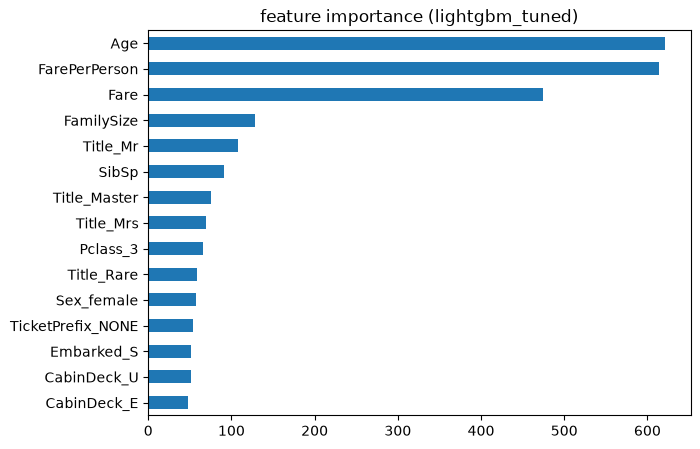

In [6]:
best_name = max(results, key=lambda name: results[name]["mean"])
best_pipeline = make_pipeline(candidates[best_name])
best_pipeline.fit(X_train, y_train)
print(f"selected: {best_name}")

importance = pd.Series(
    best_pipeline["model"].feature_importances_,
    index=best_pipeline["preprocessor"].get_feature_names_out(),
    name="importance",
).sort_values(ascending=False)

ax = importance.head(15).iloc[::-1].plot.barh(figsize=(7, 5))
ax.set_title(f"feature importance ({best_name})")

## 4. 提出ファイルを書き出す

In [7]:
y_pred = fit_predict(best_pipeline, X_train, y_train, X_test)
filepath_submission = save_submission(
    df_test["PassengerId"], y_pred, name="submission_lgbm"
)

df_submission = pd.read_csv(filepath_submission)
print(df_submission.shape, df_submission["Survived"].mean().round(3))
df_submission.head()

2026-08-01 00:14:53,746 - titanic.modeling:130[INFO] - Wrote /Users/yu9824/projects/titanic/data/processed/submissions/submission_lgbm.csv (survival rate 0.373)


(418, 2) 0.373


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1


ベースラインとの予測差分を見ておくと、どれくらい変わったかが掴める。

In [8]:
filepath_baseline = filepath_submission.parent / "submission_baseline.csv"
if filepath_baseline.is_file():
    baseline = pd.read_csv(filepath_baseline)["Survived"].to_numpy()
    n_diff = int(np.sum(baseline != df_submission["Survived"].to_numpy()))
    print(f"baseline と異なる予測: {n_diff} / {len(baseline)} 件")

baseline と異なる予測: 48 / 418 件


## 5. 提出

```bash
kaggle competitions submit -c titanic \
  -f data/processed/submissions/submission_lgbm.csv \
  -m "LGBM tuned + FE (Title/FamilySize/CabinDeck), CV acc=0.832"

kaggle competitions submissions -c titanic
```

## 次にやること

- **CV と Public LB の差を見る。** Public LB は test 418 件の一部だけなので
  ノイズが大きい。LB を追いすぎると過学習する（"LB probing"）。
  CV を信じるのが基本。
- `Age` を `Title` 別の中央値で補完する、`Ticket` 共有グループの生存を
  使う（有名なリーク系特徴量）など、特徴量をさらに足す。
- Optuna でハイパーパラメータ探索、複数モデルのアンサンブル。

コマンド一覧と全体の流れは [_notes/kaggle-workflow.md](../_notes/kaggle-workflow.md)
にまとめてある。